100%|██████████| 9.91M/9.91M [00:00<00:00, 15.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 409kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.85MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.5MB/s]


Epoch [1/5], Loss: 465.1797


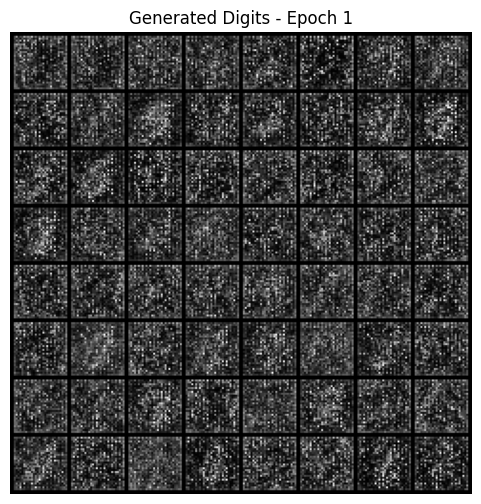

Epoch [2/5], Loss: 248.2151


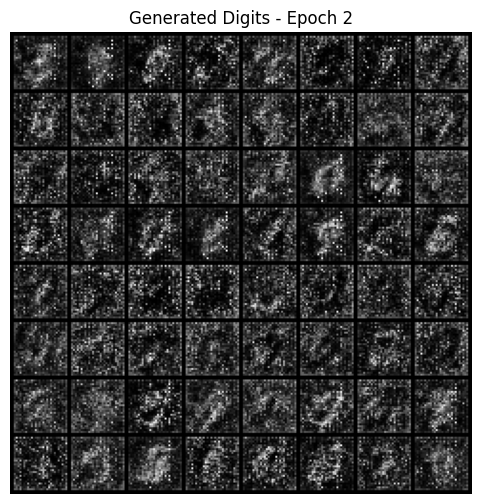

Epoch [3/5], Loss: 190.0768


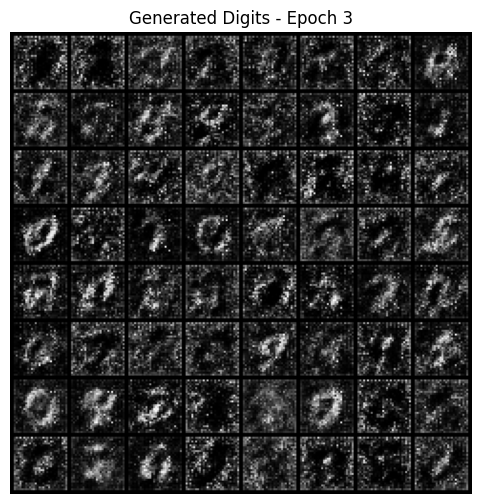

Epoch [4/5], Loss: 141.8866


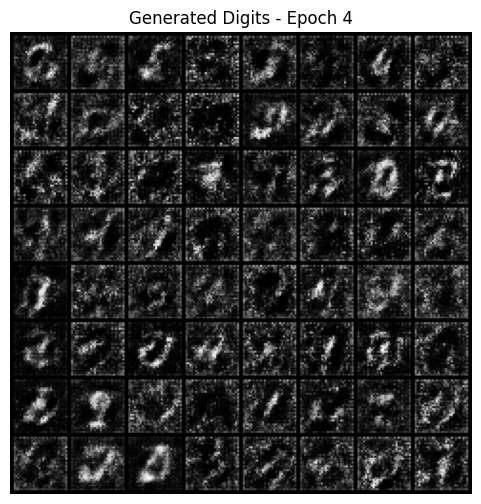

Epoch [5/5], Loss: 122.0346


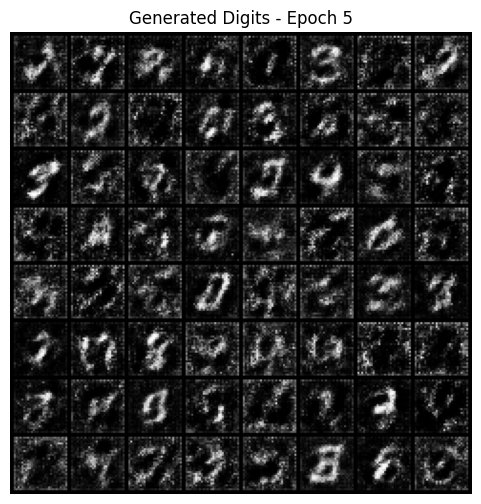

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

image_size = 28
batch_size = 32
latent_dim = 20
num_epochs = 5
learning_rate = 0.001

transform = transforms.Compose([
    transforms.Resize(image_size),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Using MNIST instead of CelebA to avoid Google Drive download limits
dataset = datasets.MNIST(
    root="data",
    train=True,
    download=True,
    transform=transform
)

dataset = Subset(dataset, range(1000))
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)


class Encoder(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(1, 32, 4, 2, 1), # 1 channel for MNIST
            nn.ReLU(),
            nn.Conv2d(32, 64, 4, 2, 1),
            nn.BatchNorm2d(64),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(64 * 7 * 7, latent_dim)
        self.fc_logvar = nn.Linear(64 * 7 * 7, latent_dim)

    def forward(self, x):
        x = self.conv(x)
        x = x.view(x.size(0), -1)
        return self.fc_mu(x), self.fc_logvar(x)


class Decoder(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()

        self.fc = nn.Linear(latent_dim, 64 * 7 * 7)

        self.deconv = nn.Sequential(
            nn.ConvTranspose2d(64, 32, 4, 2, 1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 1, 4, 2, 1),
            nn.Tanh()
        )

    def forward(self, z):
        x = self.fc(z)
        x = x.view(x.size(0), 64, 7, 7)
        return self.deconv(x)


class VAE(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.encoder = Encoder(latent_dim)
        self.decoder = Decoder(latent_dim)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        mu, logvar = self.encoder(x)
        z = self.reparameterize(mu, logvar)
        return self.decoder(z), mu, logvar


def vae_loss(recon_x, x, mu, logvar):
    recon_loss = F.mse_loss(recon_x, x, reduction="sum")
    kl_div = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )
    return recon_loss + kl_div


model = VAE(latent_dim).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

for epoch in range(num_epochs):
    model.train()
    total_loss = 0

    for images, _ in dataloader:
        images = images.to(device)

        recon, mu, logvar = model(images)
        loss = vae_loss(recon, images, mu, logvar)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(
        f"Epoch [{epoch + 1}/{num_epochs}], "
        f"Loss: {total_loss / len(dataset):.4f}"
    )

    model.eval()

    with torch.no_grad():
        z = torch.randn(64, latent_dim).to(device)
        sample_images = model.decoder(z).cpu()
        sample_images = sample_images * 0.5 + 0.5

        grid = torchvision.utils.make_grid(
            sample_images, nrow=8
        )

        plt.figure(figsize=(6, 6))
        plt.imshow(grid[0], cmap="gray")
        plt.axis("off")
        plt.title(f"Generated Digits - Epoch {epoch + 1}")
        plt.show()